In [1]:
import numpy as np
import torch, torchvision, medmnist
import matplotlib.pyplot as plt
import teste_imagens_medicas as utils
import os

# Construindo dataloader

In [2]:
dataloaders = utils.get_dataloaders()

Random.default_rng:  Generator(PCG64)
Random.default_rng:  Generator(PCG64)
Random.default_rng:  Generator(PCG64)
<class 'dict'>
{'train': <torch.utils.data.dataloader.DataLoader object at 0x0000028246B3F590>, 'val': <torch.utils.data.dataloader.DataLoader object at 0x0000028246AE1250>, 'test': <torch.utils.data.dataloader.DataLoader object at 0x00000282468D7C20>}


In [3]:
dataloaders

{'train': <torch.utils.data.dataloader.DataLoader at 0x28246b3f590>,
 'val': <torch.utils.data.dataloader.DataLoader at 0x28246ae1250>,
 'test': <torch.utils.data.dataloader.DataLoader at 0x282468d7c20>}

# Visualizando dataloader

In [4]:
print("Tipo dos dataloaders: ", type(dataloaders.values()))
print(dataloaders.values())
print(dataloaders.items())

Tipo dos dataloaders:  <class 'dict_values'>
dict_values([<torch.utils.data.dataloader.DataLoader object at 0x0000028246B3F590>, <torch.utils.data.dataloader.DataLoader object at 0x0000028246AE1250>, <torch.utils.data.dataloader.DataLoader object at 0x00000282468D7C20>])
dict_items([('train', <torch.utils.data.dataloader.DataLoader object at 0x0000028246B3F590>), ('val', <torch.utils.data.dataloader.DataLoader object at 0x0000028246AE1250>), ('test', <torch.utils.data.dataloader.DataLoader object at 0x00000282468D7C20>)])


In [5]:
treino = dataloaders["train"]
val = dataloaders["val"]
teste = dataloaders["test"]

In [6]:
print(len(treino))
print(len(val))
print(len(teste))

76
9
15


In [7]:
print(treino.dataset)
l = utils.get_labels(treino.dataset)
print(len(l))
l = l[:10]
print(l)
ll = np.append(l, 0)
print(l)
c_l = np.bincount(ll)
print(c_l)



2428
[0 1 0 1 1 1 0 0 0 0]
[0 1 0 1 1 1 0 0 0 0]
[7 4]


In [8]:
def class_distribution(dataset, name):
    counts = np.bincount(utils.get_labels(dataset))
    print(f"\n{name}")
    for label, count in enumerate(counts):
        print(f"{'Normal' if label == 0 else 'Pneumonia' }: {count} ({count / counts.sum() * 100:.2f}%)")
class_distribution(treino.dataset, "TRAIN (balanceado)")
class_distribution(val.dataset, "VALIDATION (balanceado)")
class_distribution(teste.dataset, "TEST (balanceado)")


TRAIN (balanceado)
Normal: 1214 (50.00%)
Pneumonia: 1214 (50.00%)

VALIDATION (balanceado)
Normal: 135 (50.00%)
Pneumonia: 135 (50.00%)

TEST (balanceado)
Normal: 234 (50.00%)
Pneumonia: 234 (50.00%)


In [9]:
test_original = utils.get_dataloaders(splits=("test",), balance=())["test"]
class_distribution(test_original.dataset, "TEST (original")

<class 'dict'>
{'test': <torch.utils.data.dataloader.DataLoader object at 0x000002824699ADE0>}

TEST (original
Normal: 234 (37.50%)
Pneumonia: 390 (62.50%)


In [10]:
dataset_original = treino.dataset.dataset

print("Dataset:", type(dataset_original))
print("Transformação:", dataset_original.transform)

Dataset: <class 'medmnist.dataset.PneumoniaMNIST'>
Transformação: Compose(
    ToTensor()
    Normalize(mean=[0.5], std=[0.5])
)


In [11]:
image, label = treino.dataset[0]
print("Shape da imagem:", image.shape)
print("Label:", label)

Shape da imagem: torch.Size([1, 128, 128])
Label: [0]


In [12]:
h = treino.dataset.dataset.labels
j = torch.tensor([0, 8, 9])
indices = torch.randperm(3)
[int(j[x]) for x in indices]

[9, 0, 8]

# Visualizando imagens

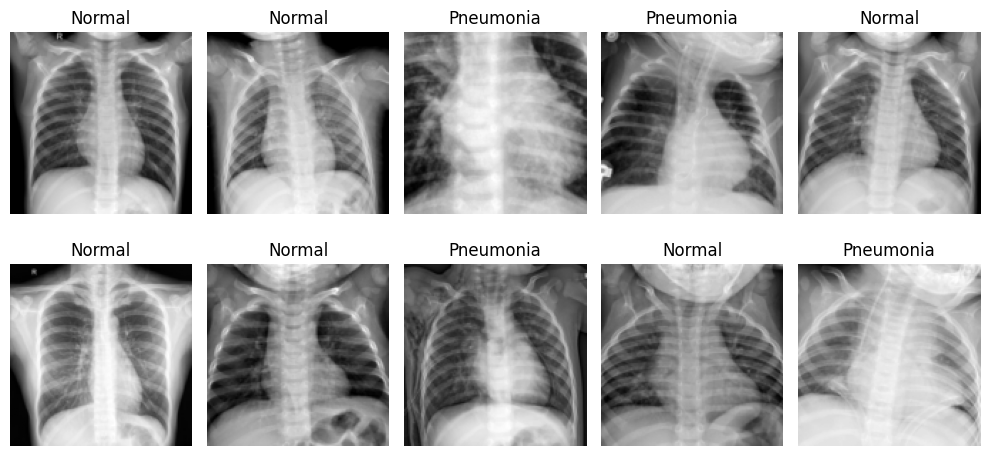

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(10,5))

for ax in axes.flat:
    image, label = treino.dataset[torch.randint(len(treino.dataset), (1,)).item()]
    ax.imshow(image.squeeze().numpy() * 0.5 + 0.5, cmap="gray")
    ax.set_title("Pneumonia" if label.item() == 1 else "Normal")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Notebook 01 - Treinamento do teacher

Constrói e treina (ResNet 18 adaptada). É o modelo mais pesado do curso. Para treinar do zero, basta mudar a flag.

Adaptações da ResNet18
- conv1: de 3 canais (RGB) para 1 canal (raio-X em escala de cinza)
- fc: de 1000 classes (ImageNet) para 2 classes (Normal / Pneumonia)

In [14]:
device = utils.get_device()

In [15]:
import torch.nn as nn

TRAIN_TEACHER = True # True = treina do zero
criterion = nn.CrossEntropyLoss()
epochs = 20

if TRAIN_TEACHER:
    teacher = utils.Teacher().to(device)
    optmizer_teacher = torch.optim.Adam(teacher.parameters(), lr=1e-3)
    history_teacher = utils.train_teacher_and_student_baseline(teacher, treino, val, epochs, criterion, optmizer_teacher, device)

    #utils.save_weights(teacher, "weights/teacher.pth")
teacher = utils.load_teacher("weights/teacher.pth", device)


Epoch 1 / 20 | Train Loss: 0.1970 | Train Acc: 0.9275 | Val Loss: 0.1719 | Val Acc: 0.9370
Epoch 2 / 20 | Train Loss: 0.0924 | Train Acc: 0.9658 | Val Loss: 0.1192 | Val Acc: 0.9519
Epoch 3 / 20 | Train Loss: 0.0598 | Train Acc: 0.9765 | Val Loss: 0.1746 | Val Acc: 0.9407
Epoch 4 / 20 | Train Loss: 0.0741 | Train Acc: 0.9728 | Val Loss: 0.2390 | Val Acc: 0.9148
Epoch 5 / 20 | Train Loss: 0.0591 | Train Acc: 0.9798 | Val Loss: 0.1378 | Val Acc: 0.9519
Epoch 6 / 20 | Train Loss: 0.0343 | Train Acc: 0.9885 | Val Loss: 0.1022 | Val Acc: 0.9481
Epoch 7 / 20 | Train Loss: 0.0290 | Train Acc: 0.9868 | Val Loss: 0.3712 | Val Acc: 0.9000
Epoch 8 / 20 | Train Loss: 0.0439 | Train Acc: 0.9843 | Val Loss: 0.0939 | Val Acc: 0.9556
Epoch 9 / 20 | Train Loss: 0.0065 | Train Acc: 0.9984 | Val Loss: 0.1221 | Val Acc: 0.9667
Epoch 10 / 20 | Train Loss: 0.0252 | Train Acc: 0.9914 | Val Loss: 0.1076 | Val Acc: 0.9704
Epoch 11 / 20 | Train Loss: 0.0398 | Train Acc: 0.9856 | Val Loss: 0.0614 | Val Acc: 0.97

FileNotFoundError: [Errno 2] No such file or directory: 'weights/teacher.pth'